## 1. RRUFF dataset

Get an idea of how the dataset looks.

In [69]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sys
import os

# Go up to the root folder, then go into the src folder
sys.path.append(os.path.abspath(os.path.join("..", "src")))

# This will now find mineral_id inside src/
from mineral_id.io import read_rruff_metadata, read_rruff_spectrum


# Identify project root, even when running from notebooks/
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "rruff"
    / "excellent_unoriented"
)


print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Directory exists:", DATA_DIR.exists())

Project root: c:\Users\pc\conformal-mineral-identification
Data directory: c:\Users\pc\conformal-mineral-identification\data\raw\rruff\excellent_unoriented
Directory exists: True


In [70]:
# Find all text files recursively
all_files = sorted(DATA_DIR.rglob("*.txt"))

print(f"Total text files found: {len(all_files)}")

# Select processed Raman spectra only
processed_files = [
    file for file in all_files
    if "Raman_Data_Processed" in file.name
]

print(f"Processed Raman spectra: {len(processed_files)}")

# Display examples
for file in processed_files[:5]:
    print(file.name)

Total text files found: 11340
Processed Raman spectra: 5784
Abellaite__R250095__Raman__532______Raman_Data_Processed__b342e40f190721ad0c8fed30ccc2.txt
Abelsonite__R070007__Raman__532______Raman_Data_Processed__cd49494835f9f72e0d7c172ad2b4.txt
Abhurite__R060227__Raman__532______Raman_Data_Processed__0ffb340f1f86044a5495110ef799.txt
Abhurite__R060227__Raman__780______Raman_Data_Processed__3263dc32f17fefd0f600a3dc0e35.txt
Actinolite__R040063__Raman__514______Raman_Data_Processed__9ec00ea798feeec5664b1c58352b.txt


In [71]:
records = []

for file in processed_files:

    parts = file.name.split("__")

    if len(parts) < 2:
        continue

    mineral = parts[0]
    rruff_id = parts[1]

    records.append({
        "mineral": mineral,
        "rruff_id": rruff_id,
        "filename": file.name,
        "path": str(file)
    })

catalog = pd.DataFrame(records)

print(f"Number of valid records: {len(catalog)}")

display(catalog.head())

Number of valid records: 5784


,mineral,rruff_id,filename,path
0,Abellaite,R250095,Abellaite__R250095__Raman__532______Raman_Data...,c:\Users\pc\conformal-mineral-identification\d...
1,Abelsonite,R070007,Abelsonite__R070007__Raman__532______Raman_Dat...,c:\Users\pc\conformal-mineral-identification\d...
2,Abhurite,R060227,Abhurite__R060227__Raman__532______Raman_Data_...,c:\Users\pc\conformal-mineral-identification\d...
3,Abhurite,R060227,Abhurite__R060227__Raman__780______Raman_Data_...,c:\Users\pc\conformal-mineral-identification\d...
4,Actinolite,R040063,Actinolite__R040063__Raman__514______Raman_Dat...,c:\Users\pc\conformal-mineral-identification\d...


In [72]:
mineral_summary = (
    catalog
    .groupby("mineral")
    .agg(
        n_spectra=("filename", "count"),
        n_specimens=("rruff_id", "nunique")
    )
    .sort_values("n_specimens", ascending=False)
)
print(f"Number of unique minerals: {len(mineral_summary)}")
print(f"Number of unique specimens: {catalog['rruff_id'].nunique()}")
print(f"Number of unique spectra: {len(catalog)}")
display(mineral_summary.head(25))

Number of unique minerals: 1970
Number of unique specimens: 3267
Number of unique spectra: 5784


,n_spectra,n_specimens
mineral,,
Grossular,42,19
Diamond,30,13
Beryl,26,13
Fluorapatite,22,13
Diopside,23,13
Andradite,27,13
Enstatite,22,12
Epidote,29,12
Elbaite,23,11


In [73]:
# Select the first available spectrum
sample_file = Path(catalog.iloc[0]["path"])

print("Filename:")
print(sample_file.name)

print("\nFirst 25 lines of the file:")

with open(sample_file, "r", errors="replace") as f:
    for i in range(25):
        line = f.readline()

        if not line:
            break

        print(line.rstrip())

Filename:
Abellaite__R250095__Raman__532______Raman_Data_Processed__b342e40f190721ad0c8fed30ccc2.txt

First 25 lines of the file:
##NAMES=Abellaite
##RRUFFID=R250095
##IDEAL CHEMISTRY=NaPb_2_(CO_3_)_2_(OH)
##LOCALITY=Eureka mine, Lleida province, Catalonia, Spain
##OWNER=Natural History Museum of Barcelona
##SOURCE=Jordi IbÃ¡Ã±ez-Insa
##DESCRIPTION=Aggregates of subhedral and pseudohexagonal colorless to white platelets.  Type sample, described in IbÃ¡Ã±ez-Insa et al (2017)
##STATUS=The identification of this mineral has been confirmed by X-ray diffraction and chemical analysis
##URL=https://www.rruff.net/odr/rruff_sample/R250095
##MEASURED CHEMISTRY=Na_0.96_Ca_0.04_Pb_1.98_(CO_3_)_2_(OH)
##DIFFRACTION SAMPLE DESCRIPTION=Powder, profile is calculated
##CELL PARAMETERS=a: 5.254 b: 5.254 c: 13.45 alpha: 90 beta: 90 gamma: 120 volume: 321.5 crystal system: hexagonal
##FILETYPE=Raman Processed
##RAMAN WAVELENGTH=532

   50.00000     ,  0.0000000E+00
   50.39000     ,   18.93085
   50.78010

In [74]:
# Select the first available spectrum
sample_file = Path(catalog[catalog["mineral"] == "unknown"].iloc[0]["path"])

print("Filename:")
print(sample_file.name)

print("\nFirst 25 lines of the file:")

with open(sample_file, "r", errors="replace") as f:
    for i in range(25):
        line = f.readline()

        if not line:
            break

        print(line.rstrip())

Filename:
unknown__R060412__Raman__532______Raman_Data_Processed__0c6347fae9b685008806093cf8f6.txt

First 25 lines of the file:
##NAMES=unknown
##RRUFFID=R060412
##IDEAL CHEMISTRY=
##LOCALITY=San Nicolas, Badajoz Province, Spain
##OWNER=RRUFF
##SOURCE=Bob Jenkins
##DESCRIPTION=Pale yellow fine-grained aggregate on quartz
##STATUS=The identification of this mineral is not yet confirmed
##URL=https://www.rruff.net/odr/rruff_sample/R060412
##FILETYPE=Raman Processed
##RAMAN WAVELENGTH=532

118.147, 0.000
118.629, 1.023
119.111, 10.474
119.593, 32.933
120.075, 118.566
120.558, 240.337
121.040, 363.430
121.522, 454.399
122.004, 525.553
122.486, 606.014
122.968, 715.830
123.450, 837.429
123.932, 950.009


## 2. Inspecting individual Raman spectra

In this section, we inspect the metadata and numerical
structure of individual RRUFF Raman files.

The objective is to understand the spectral representation
before designing the preprocessing pipeline.

In [75]:
# Select our first spectrum
sample_path = Path(catalog.iloc[0]["path"])

# Load metadata and numerical data
sample_metadata = read_rruff_metadata(sample_path)

sample_spectrum = read_rruff_spectrum(sample_path)

# Display important metadata
for key in [
    "NAMES",
    "RRUFFID",
    "IDEAL CHEMISTRY",
    "RAMAN WAVELENGTH",
    "FILETYPE"
]:
    print(f"{key}: {sample_metadata.get(key)}")

# Display first observations
display(sample_spectrum.head(10))

# Basic information
print("\nNumber of spectral points:", len(sample_spectrum))

print(
    "Raman shift range:",
    sample_spectrum["raman_shift_cm1"].min(),
    "to",
    sample_spectrum["raman_shift_cm1"].max(),
    "cm^-1"
)

print(
    "Intensity range:",
    sample_spectrum["intensity"].min(),
    "to",
    sample_spectrum["intensity"].max()
)

NAMES: Abellaite
RRUFFID: R250095
IDEAL CHEMISTRY: NaPb_2_(CO_3_)_2_(OH)
RAMAN WAVELENGTH: 532
FILETYPE: Raman Processed


,raman_shift_cm1,intensity
0,50.0000,0.00000
1,50.3900,18.93085
2,50.7801,37.99342
3,51.1701,53.24957
4,51.5602,63.66582
5,51.9502,67.95094
6,52.3403,66.39629
7,52.7303,60.09546
8,53.1204,50.84476
9,53.5104,41.60542



Number of spectral points: 3209
Raman shift range: 50.0 to 1301.27 cm^-1
Intensity range: 0.0 to 90.30946


In [76]:
x = sample_spectrum["raman_shift_cm1"].to_numpy()
y = sample_spectrum["intensity"].to_numpy()

# Check that the Raman shift is strictly increasing
strictly_increasing = np.all(np.diff(x) > 0)

# Check duplicate Raman shift values
duplicate_shifts = sample_spectrum[
    "raman_shift_cm1"
].duplicated().sum()

# Check for missing and infinite values
finite_values = np.isfinite(x).all() and np.isfinite(y).all()

print("Strictly increasing Raman shift:", strictly_increasing)
print("Duplicate Raman shifts:", duplicate_shifts)
print("All values finite:", finite_values)

Strictly increasing Raman shift: True
Duplicate Raman shifts: 0
All values finite: True


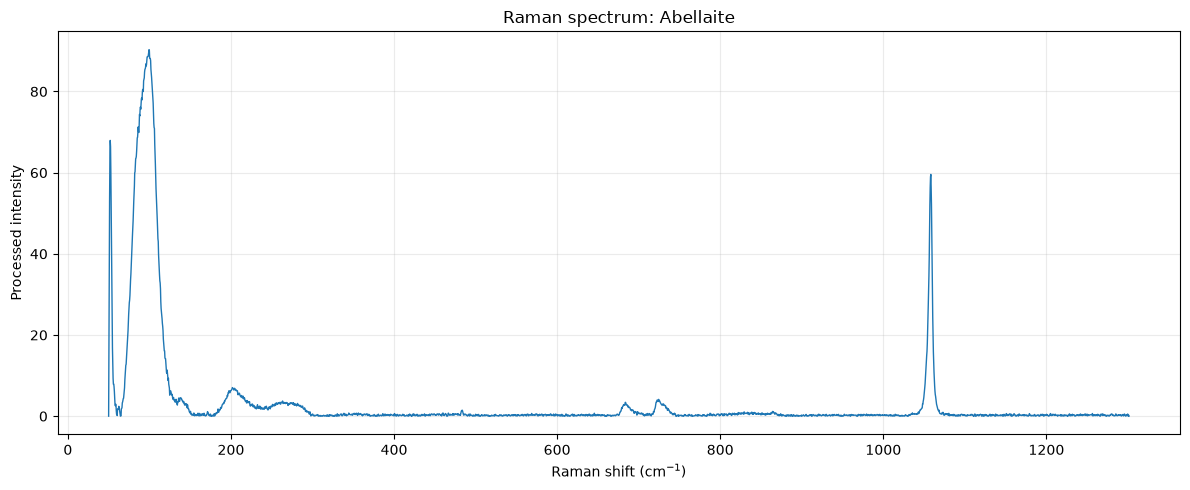

In [77]:
plt.figure(figsize=(12, 5))

plt.plot(
    sample_spectrum["raman_shift_cm1"],
    sample_spectrum["intensity"],
    linewidth=1
)

plt.xlabel("Raman shift (cm$^{-1}$)")
plt.ylabel("Processed intensity")
plt.title(
    f"Raman spectrum: {sample_metadata.get('NAMES')}"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [78]:
# Number of independent RRUFF IDs per mineral
specimens_per_mineral = (
    catalog.groupby("mineral")["rruff_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Count classes meeting different minimum requirements
thresholds = [5, 8, 10, 12, 15, 20]

for threshold in thresholds:

    n_classes = (specimens_per_mineral >= threshold).sum()

    print(
        f"Classes with at least {threshold} specimens: "
        f"{n_classes}"
    )

Classes with at least 5 specimens: 68
Classes with at least 8 specimens: 25
Classes with at least 10 specimens: 16
Classes with at least 12 specimens: 8
Classes with at least 15 specimens: 1
Classes with at least 20 specimens: 0


In [79]:
# Extract laser wavelength from filenames
catalog["laser_nm"] = catalog["filename"].str.extract(
    r"__Raman__(\d+)__"
)

# Number of spectra, specimens and minerals per wavelength
laser_summary = (
    catalog
    .groupby("laser_nm", dropna=False)
    .agg(
        n_spectra=("filename", "count"),
        n_specimens=("rruff_id", "nunique"),
        n_minerals=("mineral", "nunique")
    )
    .sort_values("n_spectra", ascending=False)
)

display(laser_summary)

,n_spectra,n_specimens,n_minerals
laser_nm,,,
532,2921,2921,1787
780,1728,1728,1129
785,731,731,567
514,380,379,239
NaN,14,14,14
633,5,5,5
632,2,2,2
458,1,1,1
515,1,1,1


In [80]:
# Check whether an RRUFF ID appears with multiple mineral labels
labels_per_id = (
    catalog.groupby("rruff_id")["mineral"]
    .nunique()
)

conflicting_ids = labels_per_id[labels_per_id > 1]

print("Total unique RRUFF IDs:", len(labels_per_id))
print("IDs associated with multiple mineral labels:", len(conflicting_ids))

if len(conflicting_ids) > 0:
    display(
        catalog[
            catalog["rruff_id"].isin(conflicting_ids.index)
        ].sort_values("rruff_id")
    )

Total unique RRUFF IDs: 3267
IDs associated with multiple mineral labels: 2


,mineral,rruff_id,filename,path,laser_nm
864,Bromellite,R050194,Bromellite__R050194__Raman__514______Raman_Dat...,c:\Users\pc\conformal-mineral-identification\d...,514
2010,Fluorapatite,R050194,Fluorapatite__R050194__Raman__514______Raman_D...,c:\Users\pc\conformal-mineral-identification\d...,514
2011,Fluorapatite,R050194,Fluorapatite__R050194__Raman__780______Raman_D...,c:\Users\pc\conformal-mineral-identification\d...,780
3548,Molybdomenite,R230009,Molybdomenite__R230009__Raman__532______Raman_...,c:\Users\pc\conformal-mineral-identification\d...,532
5357,unknown,R230009,unknown__R230009__Raman__780______Raman_Data_P...,c:\Users\pc\conformal-mineral-identification\d...,780


## 3. Data integrity and spectral consistency

We investigate:
- Conflicting mineral labels associated with the same specimen.
- Consistency between filenames and metadata headers.
- Distribution of excitation wavelengths.
- Variation in spectral resolution and Raman shift ranges.

In [81]:
suspect_ids = ["R050194", "R230009"]

suspect_rows = catalog[
    catalog["rruff_id"].isin(suspect_ids)
].sort_values(["rruff_id", "mineral", "filename"])

for _, row in suspect_rows.iterrows():

    metadata = read_rruff_metadata(Path(row["path"]))

    print("\n" + "=" * 80)
    print("Filename:", row["filename"])
    print("Mineral from filename:", row["mineral"])
    print("RRUFF ID from filename:", row["rruff_id"])

    print("Mineral from header:", metadata.get("NAMES"))
    print("RRUFF ID from header:", metadata.get("RRUFFID"))
    print("Identification status:", metadata.get("STATUS"))
    print("Laser wavelength:", metadata.get("RAMAN WAVELENGTH"))
    print("URL:", metadata.get("URL"))


Filename: Bromellite__R050194__Raman__514______Raman_Data_Processed__a163a0ea3a86304b070502f8d8b9.txt
Mineral from filename: Bromellite
RRUFF ID from filename: R050194
Mineral from header: Bromellite
RRUFF ID from header: X050194
Identification status: The identification of this mineral is not yet confirmed
Laser wavelength: 514
URL: https://www.rruff.net/odr/rruff_sample/X050194

Filename: Fluorapatite__R050194__Raman__514______Raman_Data_Processed__5809d03f5ca03332c8de9f3f9a46.txt
Mineral from filename: Fluorapatite
RRUFF ID from filename: R050194
Mineral from header: Fluorapatite
RRUFF ID from header: R050194
Identification status: The identification of this mineral has been confirmed by X-ray diffraction and chemical analysis
Laser wavelength: 514
URL: https://www.rruff.net/odr/rruff_sample/R050194

Filename: Fluorapatite__R050194__Raman__780______Raman_Data_Processed__2c72bba273df9297dd346c0541aa.txt
Mineral from filename: Fluorapatite
RRUFF ID from filename: R050194
Mineral from

In [82]:
laser_summary = (
    catalog
    .groupby("laser_nm", dropna=False)
    .agg(
        n_spectra=("filename", "count"),
        n_specimens=("rruff_id", "nunique"),
        n_minerals=("mineral", "nunique")
    )
    .sort_values("n_spectra", ascending=False)
)

print(laser_summary.reset_index().to_string(index=False))

print("\nTotal spectra:", laser_summary["n_spectra"].sum())

laser_nm  n_spectra  n_specimens  n_minerals
     532       2921         2921        1787
     780       1728         1728        1129
     785        731          731         567
     514        380          379         239
     NaN         14           14          14
     633          5            5           5
     632          2            2           2
     458          1            1           1
     515          1            1           1
      53          1            1           1

Total spectra: 5784


In [83]:
unusual_wavelengths = catalog[
    catalog["laser_nm"].isna()
    | ~catalog["laser_nm"].isin(
        ["532", "780", "785", "514", "633", "632", "458", "515"]
    )
]

display(
    unusual_wavelengths[
        ["mineral", "rruff_id", "filename", "laser_nm"]
    ].to_string(index=False)
)

'           mineral  rruff_id                                                                                              filename laser_nm\n         Adachiite R230014-3        Adachiite__R230014-3__Raman__514-5______Raman_Data_Processed__85bb1e9626093899edcc5b738568.txt      NaN\n     Davidlloydite   R130015           Davidlloydite__R130015__Raman________Raman_Data_Processed__7db6304cc818bc77d27ddac0e8ec.txt      NaN\n           Flamite   R150148            Flamite__R150148__Raman__514-5______Raman_Data_Processed__01e4dafccf39bb8acd446f7bff5c.txt      NaN\n     Gysinite-(Ce)   R250121         Gysinite-(Ce)__R250121__Raman__53______Raman_Data_Processed__1afa605821c0c2fddc073bad4789.txt       53\n    Karlseifertite   R250091          Karlseifertite__R250091__Raman________Raman_Data_Processed__a1fbae1861d2557b8e2886978af1.txt      NaN\n       Kazanskyite   R130020        Kazanskyite__R130020__Raman__532nm______Raman_Data_Processed__2f836ed870ccf06edead9f432d13.txt      NaN\n      Lecoqi

In [84]:
rng = np.random.default_rng(42)

sampled_files = rng.choice(
    processed_files,
    size=min(100, len(processed_files)),
    replace=False
)

grid_records = []

for file in sampled_files:

    try:
        spectrum = read_rruff_spectrum(file)

        x = spectrum["raman_shift_cm1"].to_numpy()
        differences = np.diff(x)

        grid_records.append({
            "filename": file.name,
            "n_points": len(x),
            "shift_min": x.min(),
            "shift_max": x.max(),
            "step_median": np.median(differences),
            "step_std": np.std(differences)
        })

    except Exception as error:
        print(f"Could not read {file.name}: {error}")

grid_stats = pd.DataFrame(grid_records)

display(
    grid_stats[
        ["n_points", "shift_min", "shift_max",
         "step_median", "step_std"]
    ].describe().round(4)
)

,n_points,shift_min,shift_max,step_median,step_std
count,100.0000,100.0000,100.0000,100.0000,100.0000
mean,2296.3800,139.8852,1304.7335,0.5329,0.0095
std,356.0312,38.8255,62.5226,0.2106,0.0509
min,1055.0000,50.0000,1188.8400,0.0000,0.0001
25%,2297.5000,110.5701,1284.5872,0.4821,0.0002
50%,2371.5000,141.1956,1297.1635,0.4821,0.0002
75%,2441.2500,165.3263,1303.0160,0.4821,0.0002
max,3436.0000,238.9841,1527.3360,1.2800,0.4876


## 4. Building a metadata-validated dataset catalogue

The original filenames are used to identify potential metadata
inconsistencies.

Mineral labels and specimen identifiers are extracted from
the RRUFF file headers and used as the primary metadata.

We also retain the original filename fields for quality control.

In [85]:
metadata_records = []
metadata_errors = []

for i, file in enumerate(processed_files):

    try:
        metadata = read_rruff_metadata(file)

        parts = file.name.split("__")

        record = {
            # Information from filename
            "filename_mineral": parts[0] if len(parts) > 0 else None,
            "filename_rruff_id": parts[1] if len(parts) > 1 else None,
            "filename_laser_token": parts[3] if len(parts) > 3 else None,

            # Information from metadata header
            "mineral": metadata.get("NAMES"),
            "rruff_id": metadata.get("RRUFFID"),
            "laser_wavelength_raw": metadata.get("RAMAN WAVELENGTH"),
            "status": metadata.get("STATUS"),
            "filetype": metadata.get("FILETYPE"),

            # File information
            "filename": file.name,
            "path": str(file)
        }

        metadata_records.append(record)

    except Exception as error:

        metadata_errors.append({
            "filename": file.name,
            "error": str(error)
        })

metadata_catalog = pd.DataFrame(metadata_records)

print("Successfully processed:", len(metadata_catalog))
print("Metadata errors:", len(metadata_errors))

display(metadata_catalog.head())

Successfully processed: 5784
Metadata errors: 0


,filename_mineral,filename_rruff_id,filename_laser_token,mineral,rruff_id,laser_wavelength_raw,status,filetype,filename,path
0,Abellaite,R250095,532,Abellaite,R250095,532,The identification of this mineral has been co...,Raman Processed,Abellaite__R250095__Raman__532______Raman_Data...,c:\Users\pc\conformal-mineral-identification\d...
1,Abelsonite,R070007,532,Abelsonite,R070007,532,The identification of this mineral is confirme...,Raman Processed,Abelsonite__R070007__Raman__532______Raman_Dat...,c:\Users\pc\conformal-mineral-identification\d...
2,Abhurite,R060227,532,Abhurite,R060227,532,The identification of this mineral is confirme...,Raman Processed,Abhurite__R060227__Raman__532______Raman_Data_...,c:\Users\pc\conformal-mineral-identification\d...
3,Abhurite,R060227,780,Abhurite,R060227,780,The identification of this mineral is confirme...,Raman Processed,Abhurite__R060227__Raman__780______Raman_Data_...,c:\Users\pc\conformal-mineral-identification\d...
4,Actinolite,R040063,514,Actinolite,R040063,514,The identification of this mineral has been co...,Raman Processed,Actinolite__R040063__Raman__514______Raman_Dat...,c:\Users\pc\conformal-mineral-identification\d...


In [ ]:
metadata_catalog["mineral_name_match"] = (
    metadata_catalog["filename_mineral"].str.casefold()
    == metadata_catalog["mineral"].str.casefold()
)

metadata_catalog["rruff_id_match"] = (
    metadata_catalog["filename_rruff_id"]
    == metadata_catalog["rruff_id"]
)

metadata_catalog["laser_token_match"] = (
    metadata_catalog["filename_laser_token"]
    == metadata_catalog["laser_wavelength_raw"]
)

print("Mineral name mismatches:",
      (~metadata_catalog["mineral_name_match"]).sum())

print("RRUFF ID mismatches:",
      (~metadata_catalog["rruff_id_match"]).sum())

print("Laser token mismatches:",
      (~metadata_catalog["laser_token_match"]).sum())

Mineral name mismatches: 27
RRUFF ID mismatches: 97
Laser token mismatches: 15


In [87]:
mismatches = metadata_catalog[
    (~metadata_catalog["mineral_name_match"])
    | (~metadata_catalog["rruff_id_match"])
]

display(
    mismatches[
        [
            "filename_mineral",
            "mineral",
            "filename_rruff_id",
            "rruff_id",
            "filename",
        ]
    ].to_string(index=False)
)

'            filename_mineral                        mineral                       filename_rruff_id rruff_id                                                                                                                   filename\n                   Adachiite                      Adachiite                               R230014-3  R230014                             Adachiite__R230014-3__Raman__514-5______Raman_Data_Processed__85bb1e9626093899edcc5b738568.txt\n   Alpha-Dlactosemonohydrate    Alpha-D lactose monohydrate                                 D120008 XD120008                 Alpha-Dlactosemonohydrate__D120008__Raman__532______Raman_Data_Processed__31b4dd54a190f12f2b6abb7b5fca.txt\n   Alpha-Dlactosemonohydrate    Alpha-D lactose monohydrate                                 D120008 XD120008                 Alpha-Dlactosemonohydrate__D120008__Raman__780______Raman_Data_Processed__af33266fd53f0efba6ff1da5de3a.txt\n                 Amblygonite                    Amblygonite        

In [88]:
print(
    "Total unique specimens:",
    metadata_catalog["rruff_id"].nunique()
)

labels_per_specimen = (
    metadata_catalog
    .dropna(subset=["rruff_id", "mineral"])
    .groupby("rruff_id")["mineral"]
    .nunique()
)

conflicting_specimens = labels_per_specimen[
    labels_per_specimen > 1
]

print(
    "Specimens associated with multiple mineral labels:",
    len(conflicting_specimens)
)

if len(conflicting_specimens) > 0:

    display(
        metadata_catalog[
            metadata_catalog["rruff_id"].isin(
                conflicting_specimens.index
            )
        ][
            ["rruff_id", "mineral", "filename"]
        ]
    )

Total unique specimens: 3228
Specimens associated with multiple mineral labels: 0


In [89]:
metadata_mineral_summary = (
    metadata_catalog
    .dropna(subset=["mineral", "rruff_id"])
    .groupby("mineral")
    .agg(
        n_spectra=("filename", "count"),
        n_specimens=("rruff_id", "nunique")
    )
    .sort_values("n_specimens", ascending=False)
)

display(metadata_mineral_summary.head(25))

,n_spectra,n_specimens
mineral,,
Grossular,42,19
Beryl,26,13
Fluorapatite,22,13
Andradite,27,13
Diamond,30,13
Diopside,23,13
Epidote,29,12
Enstatite,22,12
Forsterite,25,11


In [90]:
thresholds = [5, 8, 10, 12, 15, 20]

for threshold in thresholds:

    n_classes = (
        metadata_mineral_summary["n_specimens"] >= threshold
    ).sum()

    print(
        f"Classes with at least {threshold} specimens: "
        f"{n_classes}"
    )

Classes with at least 5 specimens: 60
Classes with at least 8 specimens: 23
Classes with at least 10 specimens: 15
Classes with at least 12 specimens: 8
Classes with at least 15 specimens: 1
Classes with at least 20 specimens: 0


In [91]:
status_summary = (
    metadata_catalog
    .groupby("status", dropna=False)
    .agg(
        n_spectra=("filename", "count"),
        n_specimens=("rruff_id", "nunique")
    )
    .sort_values("n_spectra", ascending=False)
)

display(status_summary)

,n_spectra,n_specimens
status,,
The identification of this mineral has been confirmed by X-ray diffraction and chemical analysis,1953,924
The identification of this mineral is confirmed by single-crystal X-ray diffraction and chemical analysis,1260,762
The identification of this mineral has been confirmed by single-crystal X-ray diffraction,1102,644
The identification of this mineral has been confirmed only by single crystal X-ray diffraction,630,377
The identification of this mineral is not yet confirmed,473,305
The identification of this mineral has been confirmed by X-ray diffraction,153,86
The identification of this mineral has been determined only by Raman spectroscopy,86,52
The identification of this mineral has been made only by X-ray diffraction,50,30
The identification of this mineral has been confirmed only by chemical analysis,36,21


In [92]:
for status in metadata_catalog["status"].dropna().unique():

    print("\n" + "=" * 70)
    print("STATUS:", status)

    display(
        metadata_catalog[
            metadata_catalog["status"] == status
        ][
            ["mineral", "rruff_id", "filename"]
        ].head(3)
    )


STATUS: The identification of this mineral has been confirmed by X-ray diffraction and chemical analysis


,mineral,rruff_id,filename
0,Abellaite,R250095,Abellaite__R250095__Raman__532______Raman_Data...
4,Actinolite,R040063,Actinolite__R040063__Raman__514______Raman_Dat...
5,Actinolite,R040063,Actinolite__R040063__Raman__532______Raman_Dat...



STATUS: The identification of this mineral is confirmed by single-crystal X-ray diffraction and chemical analysis


,mineral,rruff_id,filename
1,Abelsonite,R070007,Abelsonite__R070007__Raman__532______Raman_Dat...
2,Abhurite,R060227,Abhurite__R060227__Raman__532______Raman_Data_...
3,Abhurite,R060227,Abhurite__R060227__Raman__780______Raman_Data_...



STATUS: The identification of this mineral has been confirmed only by single crystal X-ray diffraction


,mineral,rruff_id,filename
19,Actinolite,R120010,Actinolite__R120010__Raman__532______Raman_Dat...
20,Actinolite,R120010,Actinolite__R120010__Raman__780______Raman_Dat...
49,Aegirine,R120167,Aegirine__R120167__Raman__532______Raman_Data_...


... (18 outputs left out)


STATUS: Unconfirmed


,mineral,rruff_id,filename
1634,Dreyerite,R140327,Dreyerite__R140327__Raman__532______Raman_Data...
1635,Dreyerite,R140327,Dreyerite__R140327__Raman__780______Raman_Data...
3116,Liangjunite,R220001,Liangjunite__R220001__Raman__532______Raman_Da...



STATUS: The identification of this mineral has been confirmed by TEM diffraction and chemical analysis


,mineral,rruff_id,filename
3851,Oxyplumbopyrochlore,R240014,Oxyplumbopyrochlore__R240014__Raman__532____un...


In [93]:
wavelength_summary = (
    metadata_catalog["laser_wavelength_raw"]
    .value_counts(dropna=False)
    .rename_axis("laser_wavelength_raw")
    .reset_index(name="n_spectra")
)

display(wavelength_summary)

,laser_wavelength_raw,n_spectra
0,532,2926
1,780,1728
2,785,731
3,514,380
4,514.5,6
5,633,5
6,632,2
7,unknown,2
8,515,1
9,458,1


In [94]:
wavelength_comparison = (
    metadata_catalog
    .groupby(
        [
            "filename_laser_token",
            "laser_wavelength_raw"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="n_spectra")
    .sort_values("n_spectra", ascending=False)
)

display(wavelength_comparison.head(30))

,filename_laser_token,laser_wavelength_raw,n_spectra
7,532,532,2921
13,780,780,1728
14,785,785,731
3,514,514,380
4,514-5,514.5,6
12,633,633,5
0,,532,3
10,632,632,2
1,,unknown,2
2,458,458,1


In [95]:
wavelength_specimen_summary = (
    metadata_catalog
    .dropna(subset=[
        "laser_wavelength_raw",
        "mineral",
        "rruff_id"
    ])
    .groupby("laser_wavelength_raw")
    .agg(
        n_spectra=("filename", "count"),
        n_specimens=("rruff_id", "nunique"),
        n_minerals=("mineral", "nunique")
    )
    .sort_values("n_spectra", ascending=False)
)

display(wavelength_specimen_summary)

,n_spectra,n_specimens,n_minerals
laser_wavelength_raw,,,
532,2926,2909,1792
780,1728,1728,1130
785,731,719,567
514,380,376,239
514.5,6,6,6
633,5,5,5
632,2,2,2
unknown,2,2,2
515,1,1,1


In [96]:
rng = np.random.default_rng(42)

sampled_files = rng.choice(
    processed_files,
    size=min(100, len(processed_files)),
    replace=False
)

grid_diagnostics = []

for file in sampled_files:

    spectrum = read_rruff_spectrum(file)

    x = spectrum["raman_shift_cm1"].to_numpy()
    differences = np.diff(x)

    positive_steps = differences[differences > 0]

    median_positive_step = (
        np.median(positive_steps)
        if len(positive_steps) > 0
        else np.nan
    )

    grid_diagnostics.append({
        "filename": file.name,
        "n_points": len(x),
        "shift_min": x.min(),
        "shift_max": x.max(),
        "step_median": np.median(differences),
        "step_std": np.std(differences),
        "duplicate_steps": np.sum(differences == 0),
        "negative_steps": np.sum(differences < 0),
        "max_gap": np.max(differences),
        "gap_ratio": (
            np.max(differences) / median_positive_step
            if median_positive_step > 0
            else np.nan
        )
    })

grid_diagnostics = pd.DataFrame(grid_diagnostics)

display(
    grid_diagnostics
    .sort_values("step_std", ascending=False)
    .head(10)
)

,filename,n_points,shift_min,shift_max,step_median,step_std,duplicate_steps,negative_steps,max_gap,gap_ratio
83,Heflikite__R250030__Raman__532______Raman_Data...,3436,50.000,1388.000,0.0000,0.487641,2097,0,1.000,1.000000
38,"Natrolite__R040022perptofiberaxes,paralleltofi...",1127,89.368,1524.717,1.2720,0.070454,0,0,1.403,1.102987
90,Grossular__R050312__Raman__514______Raman_Data...,1150,52.866,1526.162,1.2800,0.065142,0,0,1.400,1.093750
68,Dioptase__R040028__Raman__514______Raman_Data_...,1114,104.516,1527.336,1.2760,0.062819,0,0,1.392,1.090909
67,Augelite__R050316__Raman__514______Raman_Data_...,1113,100.340,1522.638,1.2770,0.062812,0,0,1.392,1.090055
74,Phenakite__R040132__Raman__514______Raman_Data...,1085,128.146,1513.235,1.2755,0.061139,0,0,1.388,1.088201
10,Celestine__R050008__Raman__514______Raman_Data...,1071,115.644,1486.138,1.2790,0.060566,0,0,1.390,1.086787
95,Ferberite__R040044__Raman__514______Raman_Data...,1055,155.863,1501.465,1.2750,0.059372,0,0,1.384,1.085490
73,Stibnite__R050016_d__Raman__785______Raman_Dat...,2454,90.190,1272.823,0.4820,0.000321,0,0,0.483,1.002075
29,Bournonite__R050111_c__Raman__785______Raman_D...,2201,212.166,1272.823,0.4820,0.000321,0,0,0.483,1.002075


In [97]:
spectral_ranges = [
    (100, 1000),
    (100, 1100),
    (100, 1200),
    (150, 1100),
    (150, 1200),
    (200, 1100),
    (200, 1200),
    (250, 1100),
    (250, 1200)
]

coverage_results = []

for lower, upper in spectral_ranges:

    covers_interval = (
        (grid_diagnostics["shift_min"] <= lower)
        &
        (grid_diagnostics["shift_max"] >= upper)
    )

    n_covered = covers_interval.sum()

    coverage_results.append({
        "lower_shift": lower,
        "upper_shift": upper,
        "n_spectra": n_covered,
        "coverage_pct": 100 * n_covered / len(grid_diagnostics)
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df.round(2))

,lower_shift,upper_shift,n_spectra,coverage_pct
0,100,1000,17,17.0
1,100,1100,17,17.0
2,100,1200,17,17.0
3,150,1100,61,61.0
4,150,1200,61,61.0
5,200,1100,93,93.0
6,200,1200,92,92.0
7,250,1100,100,100.0
8,250,1200,99,99.0


## 5. Catalogue robust
Make the catalog more robust

In [98]:
import re

def normalize_name(value):
    """Normalize labels for comparison, without changing original labels."""

    if pd.isna(value):
        return ""

    return re.sub(
        r"[\W_]+",
        "",
        str(value).casefold()
    )

metadata_catalog["normalized_name_match"] = (
    metadata_catalog["filename_mineral"].apply(normalize_name)
    == metadata_catalog["mineral"].apply(normalize_name)
)

metadata_catalog["name_mismatch_type"] = np.select(
    [
        metadata_catalog["normalized_name_match"],
        metadata_catalog["filename_mineral"].str.lower().isin(
            ["unknown", "altered"]
        )
    ],
    [
        "Formatting difference only",
        "Placeholder in filename"
    ],
    default="Other difference"
)

display(
    metadata_catalog["name_mismatch_type"]
    .value_counts()
)

name_mismatch_type
Formatting difference only    5783
Placeholder in filename          1
Name: count, dtype: int64

In [99]:
display(
    metadata_catalog[
        metadata_catalog["name_mismatch_type"] != "Formatting difference only"
    ][
        [
            "filename_mineral",
            "mineral",
            "name_mismatch_type",
            "rruff_id"
        ]
    ].to_string(index=False)
)

'filename_mineral       mineral      name_mismatch_type rruff_id\n         unknown Molybdomenite Placeholder in filename  R230009'

In [100]:
def classify_id_relation(row):

    filename_id = str(row["filename_rruff_id"])
    header_id = str(row["rruff_id"])

    if filename_id == header_id:
        return "Exact match"

    if filename_id.lower() in ["unknown", "altered", "nan", ""]:
        return "Filename placeholder"

    # Some external reference IDs have an X prefix in the header
    if header_id == "X" + filename_id:
        return "Header adds X prefix"

    # Filename contains additional information after the header ID
    if filename_id.startswith(header_id):
        return "Header ID plus filename suffix"

    if header_id.startswith(filename_id):
        return "Filename ID is a header prefix"

    return "Unresolved discrepancy"


metadata_catalog["id_relation"] = metadata_catalog.apply(
    classify_id_relation,
    axis=1
)

display(
    metadata_catalog["id_relation"].value_counts()
)

id_relation
Exact match                       5687
Header ID plus filename suffix      48
Header adds X prefix                43
Unresolved discrepancy               5
Filename placeholder                 1
Name: count, dtype: int64

In [101]:
unresolved_ids = metadata_catalog[
    metadata_catalog["id_relation"] == "Unresolved discrepancy"
]

display(
    unresolved_ids[
        [
            "filename_mineral",
            "mineral",
            "filename_rruff_id",
            "rruff_id",
            "status",
            "filename"
        ]
    ].to_string(index=False)
)

'filename_mineral    mineral filename_rruff_id rruff_id                                                                                           status                                                                                         filename\n      Bromellite Bromellite           R050194  X050194                                          The identification of this mineral is not yet confirmed      Bromellite__R050194__Raman__514______Raman_Data_Processed__a163a0ea3a86304b070502f8d8b9.txt\n       Hornesite  Hornesite     RS151-1001269  R070336                                          The identification of this mineral is not yet confirmed Hornesite__RS151-1001269__Raman__532______Raman_Data_Processed__eda974c9ad0d7f87f4c210defbeb.txt\n       Hornesite  Hornesite     RS151-1001269  R070336                                          The identification of this mineral is not yet confirmed Hornesite__RS151-1001269__Raman__785______Raman_Data_Processed__86c50cdeb4ae549236aefc7c4316.txt\

In [102]:
def classify_status(status):

    if pd.isna(status):
        return "Missing"

    s = status.casefold()

    if "not yet confirmed" in s or "unconfirmed" in s:
        return "Unconfirmed"

    if "diffraction" in s:
        return "Diffraction-supported"

    if "only by raman spectroscopy" in s:
        return "Raman-only"

    if "raman spectroscopy" in s and "chemical analysis" in s:
        return "Raman + chemical analysis"

    if "chemical analysis" in s:
        return "Chemical analysis only"

    return "Other"


metadata_catalog["status_tier"] = (
    metadata_catalog["status"].apply(classify_status)
)

status_tier_summary = (
    metadata_catalog
    .groupby("status_tier")
    .agg(
        n_spectra=("filename", "count"),
        n_sample_ids=("rruff_id", "nunique"),
        n_minerals=("mineral", "nunique")
    )
    .sort_values("n_spectra", ascending=False)
)

display(status_tier_summary)

,n_spectra,n_sample_ids,n_minerals
status_tier,,,
Diffraction-supported,5173,2840,1726
Unconfirmed,486,312,286
Raman-only,86,52,37
Chemical analysis only,36,21,20
Raman + chemical analysis,3,3,3


In [103]:
status_consistency = (
    metadata_catalog
    .groupby("rruff_id")
    .agg(
        n_statuses=("status", "nunique"),
        statuses=("status", lambda x: list(x.dropna().unique())),
        mineral=("mineral", "first")
    )
)

mixed_status_ids = status_consistency[
    status_consistency["n_statuses"] > 1
]

print("Sample IDs with multiple statuses:", len(mixed_status_ids))

display(mixed_status_ids)

Sample IDs with multiple statuses: 1


,n_statuses,statuses,mineral
rruff_id,,,
R250144,2,[The identification of this mineral is confirm...,Uranoclite


In [104]:
def parse_wavelength(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip().casefold()

    if value in ["", "unknown"]:
        return np.nan

    match = re.search(r"\d+(?:\.\d+)?", value)

    if match:
        return float(match.group())

    return np.nan


metadata_catalog["wavelength_nm"] = (
    metadata_catalog["laser_wavelength_raw"]
    .apply(parse_wavelength)
)

display(
    metadata_catalog["wavelength_nm"]
    .value_counts(dropna=False)
)

wavelength_nm
532.0    2927
780.0    1728
785.0     731
514.0     380
514.5       6
633.0       5
632.0       2
NaN         2
515.0       1
458.0       1
632.8       1
Name: count, dtype: int64

### 5.1 How much data for the experiment

In [105]:
data_532 = metadata_catalog[
    metadata_catalog["wavelength_nm"] == 532
].copy()

print("Total 532 nm spectra:", len(data_532))
print(
    "Unique RRUFF sample IDs:",
    data_532["rruff_id"].nunique()
)

Total 532 nm spectra: 2927
Unique RRUFF sample IDs: 2910


In [106]:
data_532_confirmed = data_532[
    data_532["status_tier"] == "Diffraction-supported"
].copy()

print(
    "Diffraction-supported 532 nm spectra:",
    len(data_532_confirmed)
)

print(
    "Unique sample IDs:",
    data_532_confirmed["rruff_id"].nunique()
)

Diffraction-supported 532 nm spectra: 2593
Unique sample IDs: 2576


In [107]:
confirmed_mineral_summary = (
    data_532_confirmed
    .groupby("mineral")
    .agg(
        n_spectra=("filename", "count"),
        n_sample_ids=("rruff_id", "nunique")
    )
    .sort_values("n_sample_ids", ascending=False)
)

display(confirmed_mineral_summary.head(30))

,n_spectra,n_sample_ids
mineral,,
Grossular,15,15
Andradite,13,13
Diopside,13,13
Epidote,12,12
Forsterite,11,11
Enstatite,11,11
Elbaite,11,11
Beryl,11,11
Fluorapatite,10,10


In [108]:
thresholds = [5, 6, 8, 10, 12, 15]

for threshold in thresholds:

    n_classes = (
        confirmed_mineral_summary["n_sample_ids"]
        >= threshold
    ).sum()

    print(
        f"Classes with at least {threshold} sample IDs: "
        f"{n_classes}"
    )

Classes with at least 5 sample IDs: 52
Classes with at least 6 sample IDs: 39
Classes with at least 8 sample IDs: 16
Classes with at least 10 sample IDs: 12
Classes with at least 12 sample IDs: 4
Classes with at least 15 sample IDs: 1


### 5.2 The unusual Heflikite spectrum

In [109]:
heflikite_file = next(
    file for file in processed_files
    if file.name.startswith("Heflikite__R250030")
)

heflikite_spectrum = read_rruff_spectrum(heflikite_file)

x = heflikite_spectrum["raman_shift_cm1"].to_numpy()
y = heflikite_spectrum["intensity"].to_numpy()

print("Total rows:", len(x))
print("Unique Raman shifts:", len(np.unique(x)))
print("Duplicate Raman-shift rows:",
      heflikite_spectrum["raman_shift_cm1"].duplicated().sum())

print("\nMost frequent Raman shifts:")

display(
    heflikite_spectrum["raman_shift_cm1"]
    .value_counts()
    .head(15)
)

Total rows: 3436
Unique Raman shifts: 1339
Duplicate Raman-shift rows: 2097

Most frequent Raman shifts:


raman_shift_cm1
51.0    3
53.0    3
54.0    3
56.0    3
58.0    3
60.0    3
61.0    3
63.0    3
65.0    3
67.0    3
68.0    3
70.0    3
72.0    3
74.0    3
76.0    3
Name: count, dtype: int64

In [110]:
duplicate_positions = heflikite_spectrum[
    heflikite_spectrum["raman_shift_cm1"].duplicated(
        keep=False
    )
].sort_values("raman_shift_cm1")

display(duplicate_positions.head(30))

,raman_shift_cm1,intensity
0,50.0,0.000000
1,50.0,1.745567
2,51.0,7.573287
3,51.0,15.887190
4,51.0,15.384220
5,52.0,7.199450
6,52.0,3.187795
7,53.0,0.136112
8,53.0,2.655855
9,53.0,1.694355


In [111]:
with open(
    heflikite_file,
    "r",
    encoding="utf-8-sig",
    errors="replace"
) as f:

    numerical_lines = [
        line.strip()
        for line in f
        if line.strip() and not line.startswith("#")
    ]

print("\nFirst 30 numerical lines:")

for line in numerical_lines[:30]:
    print(line)


First 30 numerical lines:
50.00000     ,  0.0000000E+00
50.00000     ,   1.745567
51.00000     ,   7.573287
51.00000     ,   15.88719
51.00000     ,   15.38422
52.00000     ,   7.199450
52.00000     ,   3.187795
53.00000     ,  0.1361120
53.00000     ,   2.655855
53.00000     ,   1.694355
54.00000     ,  0.9587610
54.00000     ,   1.570335
54.00000     ,   2.910297
55.00000     ,   2.076309
55.00000     ,   2.081520
56.00000     ,   1.062683
56.00000     ,   8.346016
56.00000     ,   17.75835
57.00000     ,   25.29008
57.00000     ,   31.93263
58.00000     ,   38.67844
58.00000     ,   44.52095
58.00000     ,   47.45445
59.00000     ,   48.47401
59.00000     ,   49.57526
60.00000     ,   50.75436
60.00000     ,   53.00790
60.00000     ,   52.33281
61.00000     ,   51.72632
61.00000     ,   49.18594


## 6. Creation of Dataset


In [112]:
candidate_minerals = [
    "Grossular",
    "Andradite",
    "Diopside",
    "Epidote",
    "Forsterite",
    "Enstatite",
    "Elbaite",
    "Beryl",
    "Fluorapatite",
    "Almandine",
    "Pyrope",
    "Wendwilsonite"
]

In [113]:
# Sample IDs with inconsistent identification status
mixed_status_ids = set(
    status_consistency[
        status_consistency["n_statuses"] > 1
    ].index
)

# Unresolved filename/header identifier discrepancies
unresolved_sample_ids = set(
    unresolved_ids["rruff_id"].dropna()
)

# Combined quarantine list
quarantined_ids = mixed_status_ids | unresolved_sample_ids

print("Sample IDs quarantined:", len(quarantined_ids))
print("IDs:", sorted(quarantined_ids))

Sample IDs quarantined: 4
IDs: ['R050145', 'R070336', 'R250144', 'X050194']


In [114]:
candidate_data = metadata_catalog[
    (metadata_catalog["status_tier"] == "Diffraction-supported")
    & (metadata_catalog["mineral"].isin(candidate_minerals))
    & (metadata_catalog["rruff_id"].notna())
    & (~metadata_catalog["rruff_id"].isin(quarantined_ids))
].copy()

print("Total candidate spectra:", len(candidate_data))

print(
    "Unique candidate sample IDs:",
    candidate_data["rruff_id"].nunique()
)

Total candidate spectra: 298
Unique candidate sample IDs: 142


In [115]:
# Summary using all available wavelengths
all_wavelength_summary = (
    candidate_data
    .groupby("mineral")
    .agg(
        n_spectra_all=("filename", "count"),
        n_samples_all=("rruff_id", "nunique")
    )
)

# Summary using only 532 nm
summary_532 = (
    candidate_data[
        candidate_data["wavelength_nm"] == 532
    ]
    .groupby("mineral")
    .agg(
        n_spectra_532=("filename", "count"),
        n_samples_532=("rruff_id", "nunique")
    )
)

comparison = (
    all_wavelength_summary
    .join(summary_532)
    .fillna(0)
)

comparison["additional_sample_ids"] = (
    comparison["n_samples_all"]
    - comparison["n_samples_532"]
)

display(comparison.sort_values(
    "n_samples_all",
    ascending=False
))


,n_spectra_all,n_samples_all,n_spectra_532,n_samples_532,additional_sample_ids
mineral,,,,,
Grossular,38,17,15,15,2
Andradite,27,13,13,13,0
Fluorapatite,22,13,10,10,3
Diopside,23,13,13,13,0
Epidote,29,12,12,12,0
Beryl,23,11,11,11,0
Elbaite,23,11,11,11,0
Enstatite,21,11,11,11,0
Forsterite,25,11,11,11,0


In [116]:
wavelength_composition = (
    candidate_data
    .groupby(["mineral", "wavelength_nm"])["rruff_id"]
    .nunique()
    .unstack(fill_value=0)
)

display(wavelength_composition)

wavelength_nm,514.0,532.0,780.0,785.0
mineral,,,,
Almandine,4,10,7,3
Andradite,1,13,12,1
Beryl,4,11,7,1
Diopside,1,13,7,2
Elbaite,2,11,9,1
Enstatite,0,11,5,5
Epidote,5,12,9,3
Fluorapatite,6,10,6,0
Forsterite,4,11,9,1


In [117]:
uranoclite_records = metadata_catalog[
    metadata_catalog["rruff_id"] == "R250144"
][
    [
        "mineral",
        "rruff_id",
        "filename",
        "wavelength_nm",
        "status",
        "status_tier"
    ]
]

display(uranoclite_records.to_string(index=False))

'   mineral rruff_id                                                                                    filename  wavelength_nm                                                                                                    status           status_tier\nUranoclite  R250144 Uranoclite__R250144__Raman__532______Raman_Data_Processed__3825f092f92b8c02a4fd15a9b4d4.txt          532.0 The identification of this mineral is confirmed by single-crystal X-ray diffraction and chemical analysis Diffraction-supported\nUranoclite  R250144 Uranoclite__R250144__Raman__785______Raman_Data_Processed__781739ea58be3b4468efa48706e4.txt          785.0          The identification of this mineral has been confirmed by X-ray diffraction and chemical analysis Diffraction-supported'

### 6.1 Investigate the Heflikite

In [118]:
shift_counts = (
    heflikite_spectrum
    .groupby("raman_shift_cm1")
    .size()
)

count_distribution = (
    shift_counts
    .value_counts()
    .sort_index()
    .rename_axis("observations_per_shift")
    .reset_index(name="n_shift_positions")
)

display(count_distribution)

,observations_per_shift,n_shift_positions
0,1,1
1,2,579
2,3,759


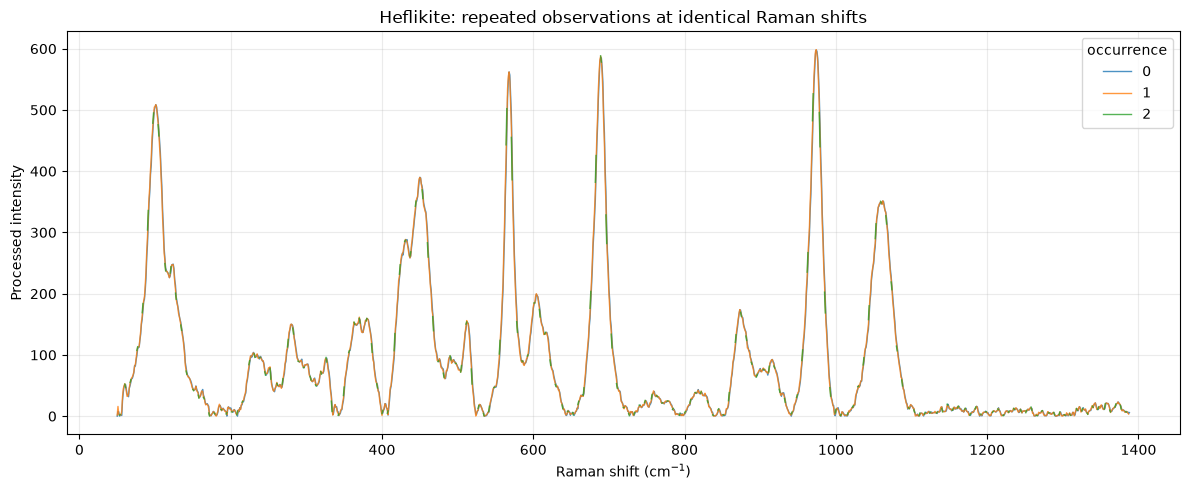

In [119]:
heflikite_inspection = heflikite_spectrum.copy()

heflikite_inspection["occurrence"] = (
    heflikite_inspection
    .groupby("raman_shift_cm1")
    .cumcount()
)

heflikite_pivot = (
    heflikite_inspection
    .pivot(
        index="raman_shift_cm1",
        columns="occurrence",
        values="intensity"
    )
)

ax = heflikite_pivot.plot(
    figsize=(12, 5),
    linewidth=1,
    alpha=0.8
)

ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Processed intensity")
ax.set_title("Heflikite: repeated observations at identical Raman shifts")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [120]:
heflikite_metadata = read_rruff_metadata(heflikite_file)

for key, value in heflikite_metadata.items():

    print(f"{key}: {value}")

NAMES: Heflikite
RRUFFID: R250030
IDEAL CHEMISTRY: Ca_2_(Al_2_Sc)(Si_2_O_7_)(SiO_4_)O(OH)
LOCALITY: Jordanow Slaski, Lower Silesia, Poland
OWNER: Mineralogical Museum at the University of Wrocław
SOURCE: Adam Pieczka
DESCRIPTION: Compositionally zoned euhedral to subhedral crystals and intergrowths with REE-bearing clinozoisite and allanite-(Ce). Type sample described in Pieczka et al (2024)
STATUS: The identification of this mineral is confirmed by single-crystal X-ray diffraction and chemical analysis
URL: https://www.rruff.net/odr/rruff_sample/R250030
MEASURED CHEMISTRY: Ca(Ca_0.729_Ce_0.125_La_0.048_Nd_0.046_Gd_0.016_Sm_0.012_Pr_0.010_Y_0.005_Eu^2+^_0.003_)AlAl[(Sc_0.449_Al_0.182_Fe^3+^_0.070_V^3+^_0.005_)(Fe^2+^_0.251_Mg_0.020_Mn_0.010_)Ti_0.014_](Si_3.006_O_11_)O(OH)
DIFFRACTION SAMPLE DESCRIPTION: Single crystal, powder profile is calculated
CELL PARAMETERS: a: 8.9383 b: 5.683 c: 10.1903 alpha: 90 beta: 115.043 gamma: 90 volume: 468.97 crystal system: monoclinic
FILETYPE: Raman 

## 7. Construction of the primary classification dataset

The primary dataset contains 12 selected mineral species,
measured at 532 nm, with RRUFF metadata indicating
diffraction-based identification evidence.

The header RRUFF ID is used as the sample grouping identifier.

In [121]:
# Selected mineral species
candidate_minerals = [
    "Grossular",
    "Andradite",
    "Diopside",
    "Epidote",
    "Forsterite",
    "Enstatite",
    "Elbaite",
    "Beryl",
    "Fluorapatite",
    "Almandine",
    "Pyrope",
    "Wendwilsonite"
]

# Identify sample IDs with genuinely inconsistent
# identification evidence categories.
evidence_counts = (
    metadata_catalog
    .groupby("rruff_id")["status_tier"]
    .nunique()
)

mixed_evidence_ids = set(
    evidence_counts[evidence_counts > 1].index
)

# Exclude unresolved filename/header ID discrepancies.
unresolved_sample_ids = set(
    unresolved_ids["rruff_id"].dropna()
)

# Construct the primary dataset.
primary_data = metadata_catalog[
    (metadata_catalog["wavelength_nm"] == 532)
    & (metadata_catalog["mineral"].isin(candidate_minerals))
    & (metadata_catalog["status_tier"] == "Diffraction-supported")
    & (metadata_catalog["rruff_id"].notna())
    & (~metadata_catalog["rruff_id"].isin(unresolved_sample_ids))
    & (~metadata_catalog["rruff_id"].isin(mixed_evidence_ids))
].copy()

primary_data = primary_data.reset_index(drop=True)

print("Total spectra:", len(primary_data))
print("Unique sample IDs:", primary_data["rruff_id"].nunique())
print("Unique minerals:", primary_data["mineral"].nunique())

Total spectra: 137
Unique sample IDs: 137
Unique minerals: 12


In [122]:
# Class distribution
final_class_summary = (
    primary_data
    .groupby("mineral")
    .agg(
        n_spectra=("filename", "count"),
        n_sample_ids=("rruff_id", "nunique")
    )
    .sort_values("n_sample_ids", ascending=False)
)

display(final_class_summary)

# Check duplicate sample IDs
duplicate_sample_ids = (
    primary_data["rruff_id"]
    .value_counts()
    .loc[lambda x: x > 1]
)

print("\nSample IDs with multiple 532 nm spectra:")
display(duplicate_sample_ids)

# Check wavelength consistency
assert primary_data["wavelength_nm"].eq(532).all()

# Check that every selected class is represented
assert set(primary_data["mineral"]) == set(candidate_minerals)

# Check that sample IDs are not duplicated
assert duplicate_sample_ids.empty

# Final validation
assert primary_data["rruff_id"].nunique() == 137

print("\nAll primary dataset validation checks passed.")

,n_spectra,n_sample_ids
mineral,,
Grossular,15,15
Andradite,13,13
Diopside,13,13
Epidote,12,12
Forsterite,11,11
Beryl,11,11
Enstatite,11,11
Elbaite,11,11
Almandine,10,10



Sample IDs with multiple 532 nm spectra:


Series([], Name: count, dtype: int64)


All primary dataset validation checks passed.


In [123]:
manifest_dir = PROJECT_ROOT / "data" / "manifests"
manifest_dir.mkdir(parents=True, exist_ok=True)

manifest = primary_data[
    [
        "mineral",
        "rruff_id",
        "wavelength_nm",
        "status",
        "filetype",
        "filename",
        "path"
    ]
].copy()

# Store relative paths rather than machine-specific
# absolute Windows paths.
manifest["relative_path"] = manifest["path"].apply(
    lambda p: Path(p).relative_to(DATA_DIR).as_posix()
)

manifest = manifest.drop(columns=["path"])

manifest_path = (
    manifest_dir / "primary_532nm_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("Manifest saved to:", manifest_path)
print("Number of records:", len(manifest))

Manifest saved to: c:\Users\pc\conformal-mineral-identification\data\manifests\primary_532nm_manifest.csv
Number of records: 137


## 8. Spectral characteristics of the primary dataset

This section investigates the spectral ranges, sampling
resolution, duplicate Raman-shift positions and intensity
characteristics of the selected 137 sample-ID groups.

In [124]:
spectral_records = []

for row in primary_data.itertuples(index=False):

    spectrum = read_rruff_spectrum(row.path)

    x = spectrum["raman_shift_cm1"].to_numpy()
    y = spectrum["intensity"].to_numpy()

    # Unique Raman-shift positions
    unique_x = np.unique(x)

    # Differences between consecutive original observations
    original_steps = np.diff(x)

    # Differences between unique sorted positions
    unique_steps = np.diff(unique_x)

    spectral_records.append({

        "mineral": row.mineral,
        "rruff_id": row.rruff_id,
        "filename": row.filename,

        "n_points": len(x),
        "n_unique_shifts": len(unique_x),
        "n_duplicate_rows": len(x) - len(unique_x),

        "shift_min": x.min(),
        "shift_max": x.max(),

        "strictly_increasing": np.all(original_steps > 0),
        "nondecreasing": np.all(original_steps >= 0),

        "median_step": np.median(unique_steps),
        "step_std": np.std(unique_steps),

        "min_intensity": y.min(),
        "max_intensity": y.max(),

        "negative_intensity_count": np.sum(y < 0),
        "finite_values": np.isfinite(x).all() and np.isfinite(y).all()
    })

spectral_audit = pd.DataFrame(spectral_records)

print("Audited spectra:", len(spectral_audit))
display(spectral_audit.head())

Audited spectra: 137


,mineral,rruff_id,filename,n_points,n_unique_shifts,n_duplicate_rows,shift_min,shift_max,strictly_increasing,nondecreasing,median_step,step_std,min_intensity,max_intensity,negative_intensity_count,finite_values
0,Almandine,R040076,Almandine__R040076__Raman__532______Raman_Data...,2399,2399,0,127.8412,1283.957,True,True,0.4821,0.000163,0.0,20254.050,0,True
1,Almandine,R040079,Almandine__R040079__Raman__532______Raman_Data...,2331,2331,0,156.7682,1280.100,True,True,0.4821,0.000164,0.0,8767.123,0,True
2,Almandine,R040168,Almandine__R040168__Raman__532______Raman_Data...,2449,2449,0,124.5917,1304.814,True,True,0.4821,0.000167,0.0,3964.730,0,True
3,Almandine,R050029,Almandine__R050029__Raman__532______Raman_Data...,2422,2422,0,133.2699,1300.475,True,True,0.4821,0.000166,0.0,12979.290,0,True
4,Almandine,R060099,Almandine__R060099__Raman__532______Raman_Data...,2414,2414,0,141.0473,1304.395,True,True,0.4821,0.000168,0.0,1933.950,0,True


In [125]:
display(
    spectral_audit[
        ["n_points", "shift_min", "shift_max",
         "median_step", "step_std", "min_intensity",
         "max_intensity"]
    ].describe().round(4)
)

,n_points,shift_min,shift_max,median_step,step_std,min_intensity,max_intensity
count,137.0000,137.0000,137.0000,137.0000,137.0000,137.0000,137.0000
mean,2428.6131,127.5990,1297.9918,0.4821,0.0002,-0.5567,8462.5495
std,58.0860,25.8201,10.1709,0.0000,0.0000,4.9059,24395.7771
min,2277.0000,88.1367,1254.4970,0.4820,0.0002,-55.2696,52.8199
25%,2393.0000,105.4713,1296.4400,0.4821,0.0002,0.0000,1099.3440
50%,2424.0000,128.9422,1302.3780,0.4821,0.0002,0.0000,2216.0110
75%,2465.0000,143.9155,1303.5310,0.4821,0.0002,0.0000,8611.6930
max,2517.0000,204.5875,1315.4570,0.4821,0.0003,0.0000,268065.6560


In [126]:
common_lower = spectral_audit["shift_min"].max()
common_upper = spectral_audit["shift_max"].min()

print("Common lower boundary:", common_lower)
print("Common upper boundary:", common_upper)
print("Common spectral width:", common_upper - common_lower)

Common lower boundary: 204.5875
Common upper boundary: 1254.497
Common spectral width: 1049.9095


In [127]:
candidate_ranges = [
    (100, 1000),
    (100, 1100),
    (150, 1100),
    (200, 1100),
    (200, 1200),
    (250, 1100),
    (250, 1200)
]

coverage_records = []

for lower, upper in candidate_ranges:

    covered = (
        (spectral_audit["shift_min"] <= lower)
        &
        (spectral_audit["shift_max"] >= upper)
    )

    coverage_records.append({
        "lower_shift": lower,
        "upper_shift": upper,
        "n_covered": int(covered.sum()),
        "coverage_pct": 100 * covered.mean()
    })

coverage_summary = pd.DataFrame(coverage_records)

display(coverage_summary.round(2))

,lower_shift,upper_shift,n_covered,coverage_pct
0,100,1000,32,23.36
1,100,1100,32,23.36
2,150,1100,113,82.48
3,200,1100,136,99.27
4,200,1200,136,99.27
5,250,1100,137,100.00
6,250,1200,137,100.00


In [128]:
class_range_summary = (
    spectral_audit
    .groupby("mineral")
    .agg(
        n_sample_ids=("rruff_id", "nunique"),
        lowest_shift=("shift_min", "min"),
        lower_q05=("shift_min", lambda x: x.quantile(0.05)),
        median_start=("shift_min", "median"),
        median_end=("shift_max", "median"),
        upper_q05=("shift_max", lambda x: x.quantile(0.05)),
        lowest_max_shift=("shift_max", "min")
    )
)

display(class_range_summary.round(2))

,n_sample_ids,lowest_shift,lower_q05,median_start,median_end,upper_q05,lowest_max_shift
mineral,,,,,,,
Almandine,10,90.49,93.39,137.16,1302.45,1281.84,1280.10
Andradite,13,90.01,90.30,122.49,1303.02,1272.64,1265.15
Beryl,11,118.87,122.54,127.31,1300.78,1273.18,1272.33
Diopside,13,90.49,90.49,133.65,1301.82,1277.74,1271.61
Elbaite,11,92.11,94.28,132.50,1304.15,1293.46,1287.61
Enstatite,11,92.19,103.50,127.36,1301.82,1286.12,1285.39
Epidote,12,91.04,100.78,140.12,1302.81,1284.89,1282.50
Fluorapatite,10,98.14,109.10,142.58,1297.78,1270.26,1258.11
Forsterite,11,91.04,91.33,94.04,1304.15,1278.55,1254.50


In [129]:
reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

spectral_audit.to_csv(
    reports_dir / "primary_spectral_audit.csv",
    index=False
)

coverage_summary.to_csv(
    reports_dir / "spectral_coverage_summary.csv",
    index=False
)

print("Spectral audit files saved.")

Spectral audit files saved.


### 8.1 Generate actual splits

In [130]:
from mineral_id.splits import make_grouped_splits

splits = make_grouped_splits(
    primary_data,
    group_col="rruff_id",
    label_col="mineral",
    train_fraction=0.60,
    calibration_fraction=0.20,
    test_fraction=0.20,
    random_state=42
)

In [131]:
for name, split_data in splits.items():

    print(f"\n{'=' * 60}")
    print(name.upper())

    print("Number of spectra:", len(split_data))
    print(
        "Number of sample IDs:",
        split_data["rruff_id"].nunique()
    )

    display(
        split_data.groupby("mineral")["rruff_id"]
        .nunique()
    )


TRAIN
Number of spectra: 82
Number of sample IDs: 82


mineral
Almandine        6
Andradite        8
Beryl            6
Diopside         8
Elbaite          7
Enstatite        7
Epidote          7
Fluorapatite     6
Forsterite       6
Grossular        9
Pyrope           6
Wendwilsonite    6
Name: rruff_id, dtype: int64


CALIBRATION
Number of spectra: 27
Number of sample IDs: 27


mineral
Almandine        2
Andradite        2
Beryl            2
Diopside         2
Elbaite          2
Enstatite        2
Epidote          3
Fluorapatite     2
Forsterite       3
Grossular        3
Pyrope           2
Wendwilsonite    2
Name: rruff_id, dtype: int64


TEST
Number of spectra: 28
Number of sample IDs: 28


mineral
Almandine        2
Andradite        3
Beryl            3
Diopside         3
Elbaite          2
Enstatite        2
Epidote          2
Fluorapatite     2
Forsterite       2
Grossular        3
Pyrope           2
Wendwilsonite    2
Name: rruff_id, dtype: int64

In [132]:
split_assignment = pd.concat(
    [
        split_data[
            ["rruff_id", "mineral"]
        ]
        .drop_duplicates()
        .assign(split=name)

        for name, split_data in splits.items()
    ],
    ignore_index=True
)

split_assignment = split_assignment.sort_values(
    ["mineral", "rruff_id"]
).reset_index(drop=True)

assignment_path = (
    PROJECT_ROOT
    / "data"
    / "manifests"
    / "primary_532nm_split_assignment.csv"
)

split_assignment.to_csv(
    assignment_path,
    index=False
)

print("Split assignment saved:", assignment_path)

Split assignment saved: c:\Users\pc\conformal-mineral-identification\data\manifests\primary_532nm_split_assignment.csv
